<a href="https://colab.research.google.com/github/NicoleLivesta/Kel2_3TID_ProjectProbstat/blob/main/Kel2_3TID_ProbabilitasdanStatistika.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

# Set style tampilan grafik
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

Saving 3TID_02_NASASoftwareDefectPrediction.xlsx to 3TID_02_NASASoftwareDefectPrediction.xlsx


In [ ]:
# Data Cleaning

# Membersihkan spasi pada nama kolom & karakter BOM jika ada
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace("ï»¿", "", regex=False)
df.columns = df.columns.str.replace("\ufeff", "", regex=False)

# Memastikan variabel utama bertipe numerik
main_vars = ['LOC_TOTAL', 'CYCLOMATIC_COMPLEXITY', 'Defect']
for col in main_vars:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Mengecek missing value pada variabel utama
print("=== CEK MISSING VALUE ===")
print(df[main_vars].isnull().sum())

# Menghapus baris yang memiliki missing value pada variabel utama
df = df.dropna(subset=main_vars)
print("\nJumlah data setelah cleaning:", len(df))

=== CEK MISSING VALUE ===
LOC_TOTAL                0
CYCLOMATIC_COMPLEXITY    0
Defect                   0
dtype: int64

Jumlah data setelah cleaning: 1676


In [ ]:
# 1. Perhitungan Statistika Deskriptif Variabel Utama
vars_main = ['LOC_TOTAL', 'CYCLOMATIC_COMPLEXITY']
summary = df[vars_main].describe().T
summary['IQR'] = summary['75%'] - summary['25%']
summary['Skewness'] = df[vars_main].skew()

print("=== STATISTIKA DESKRIPTIF VARIABEL UTAMA ===")
print(summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'Skewness']])

=== STATISTIKA DESKRIPTIF VARIABEL UTAMA ===
                        count       mean        std  min  25%  50%   75%  \
LOC_TOTAL              1676.0  20.713007  30.808052  1.0  4.0  9.0  24.0   
CYCLOMATIC_COMPLEXITY  1676.0   2.887232   4.001469  1.0  1.0  1.0   3.0   

                         max   IQR  Skewness  
LOC_TOTAL              288.0  20.0   3.44877  
CYCLOMATIC_COMPLEXITY   45.0   2.0   3.75875  


In [ ]:
# 2. Distribusi Frekuensi Defek
print("\n=== DISTRIBUSI STATUS DEFEK ===")
print(df['Defect'].value_counts())
print(df['Defect'].value_counts(normalize=True) * 100)


=== DISTRIBUSI STATUS DEFEK ===
Defect
0    1416
1     260
Name: count, dtype: int64
Defect
0    84.486874
1    15.513126
Name: proportion, dtype: float64


In [ ]:
# 3. Perbandingan Berdasarkan Status Defek
print("\n=== PERBANDINGAN METRIK BERDASARKAN DEFEK ===")
print(df.groupby('Defect')[vars_main].agg(['count', 'mean', 'median', 'std', 'min', 'max']))


=== PERBANDINGAN METRIK BERDASARKAN DEFEK ===
       LOC_TOTAL                                       CYCLOMATIC_COMPLEXITY  \
           count       mean median        std min  max                 count   
Defect                                                                         
0           1416  16.178672    6.0  24.292444   1  283                  1416   
1            260  45.407692   27.0  46.793343   2  288                   260   

                                           
            mean median       std min max  
Defect                                     
0       2.382062    1.0  3.290451   1  34  
1       5.638462    4.0  5.950249   1  45  


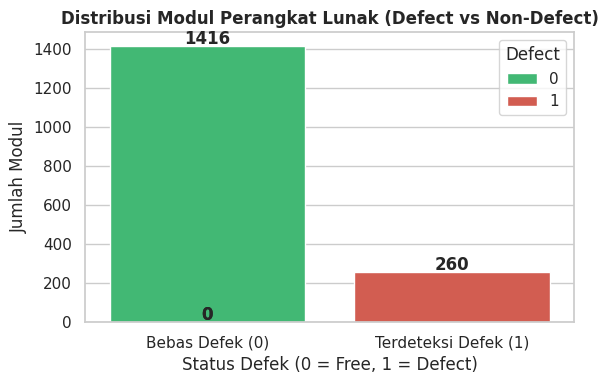

In [ ]:
# Grafik 1: Proporsi Status Defek (Bar Chart)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Defect', data=df, hue='Defect', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Modul Perangkat Lunak (Defect vs Non-Defect)', fontsize=12, fontweight='bold')
plt.xlabel('Status Defek (0 = Free, 1 = Defect)')
plt.ylabel('Jumlah Modul')
plt.xticks([0, 1], ['Bebas Defek (0)', 'Terdeteksi Defek (1)'])

# Menambahkan angka di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.savefig('1_distribusi_defect.png', dpi=300)
plt.show()

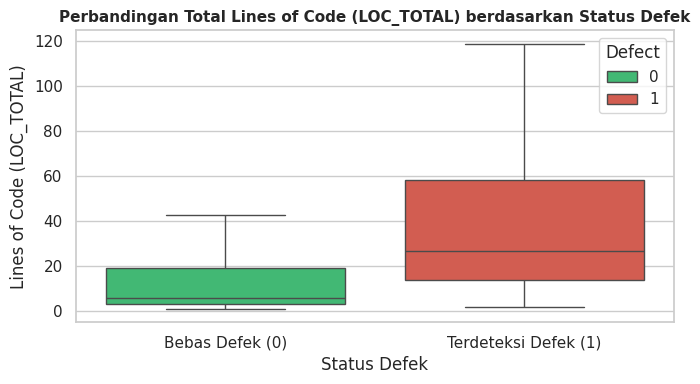

In [ ]:
# Grafik 2: Boxplot Perbandingan LOC_TOTAL berdasarkan Status Defek
plt.figure(figsize=(7, 4))
sns.boxplot(x='Defect', y='LOC_TOTAL',hue='Defect', data=df, palette=['#2ecc71', '#e74c3c'], showfliers=False)
plt.title('Perbandingan Total Lines of Code (LOC_TOTAL) berdasarkan Status Defek', fontsize=11, fontweight='bold')
plt.xlabel('Status Defek')
plt.ylabel('Lines of Code (LOC_TOTAL)')
plt.xticks([0, 1], ['Bebas Defek (0)', 'Terdeteksi Defek (1)'])
plt.tight_layout()
plt.savefig('2_boxplot_loc.png', dpi=300)
plt.show()

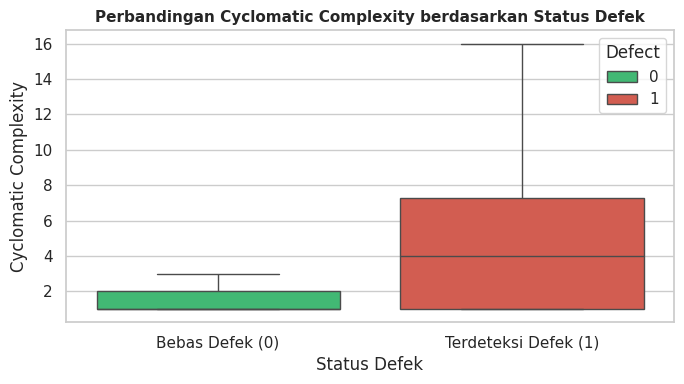

In [ ]:
# Grafik 3: Boxplot Perbandingan CYCLOMATIC_COMPLEXITY berdasarkan Status Defek
plt.figure(figsize=(7, 4))
sns.boxplot(x='Defect', y='CYCLOMATIC_COMPLEXITY', hue='Defect', data=df, palette=['#2ecc71', '#e74c3c'], showfliers=False)
plt.title('Perbandingan Cyclomatic Complexity berdasarkan Status Defek', fontsize=11, fontweight='bold')
plt.xlabel('Status Defek')
plt.ylabel('Cyclomatic Complexity')
plt.xticks([0, 1], ['Bebas Defek (0)', 'Terdeteksi Defek (1)'])
plt.tight_layout()
plt.savefig('3_boxplot_complexity.png', dpi=300)
plt.show()

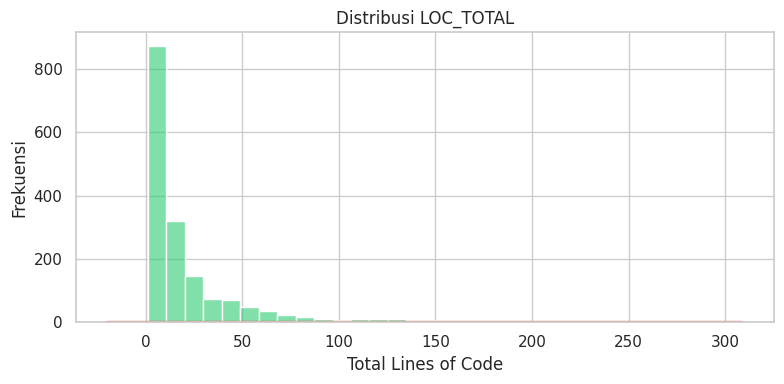

In [ ]:
# Grafik 4: Distribusi LOC_TOTAL

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='LOC_TOTAL', bins=30, color='#2ecc71', alpha=0.6)
sns.kdeplot( data=df, x='LOC_TOTAL', color='#e74c3c', linewidth=2)

plt.title('Distribusi LOC_TOTAL')
plt.xlabel('Total Lines of Code')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('4_distribusi_loc.png', dpi=300)
plt.show()

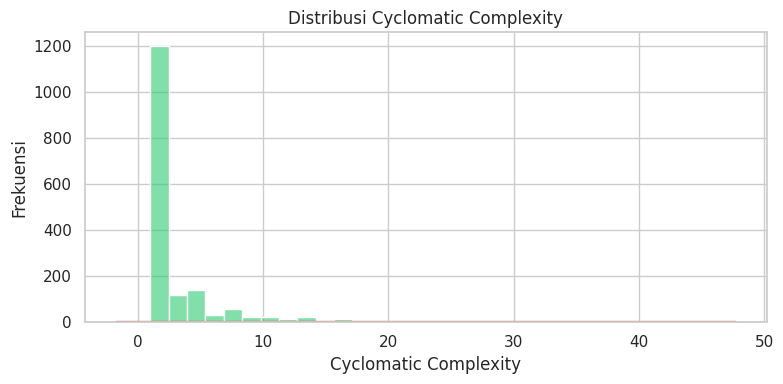

In [ ]:
# Grafik 5: Distribusi Cyclomatic Complexity

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='CYCLOMATIC_COMPLEXITY', bins=30, color='#2ecc71', alpha=0.6)
sns.kdeplot(data=df, x='CYCLOMATIC_COMPLEXITY', color='#e74c3c', linewidth=2)

plt.title('Distribusi Cyclomatic Complexity')
plt.xlabel('Cyclomatic Complexity')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('5_distribusi_complexity.png', dpi=300)
plt.show()

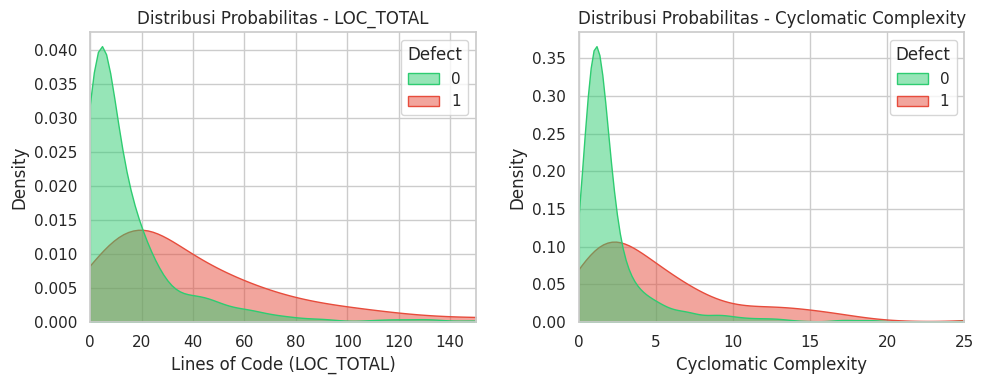

In [ ]:
# Grafik KDE Plot
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.kdeplot(data=df, x='LOC_TOTAL', hue='Defect', fill=True, common_norm=False, palette=['#2ecc71', '#e74c3c'], alpha=0.5)
plt.title('Distribusi Probabilitas - LOC_TOTAL')
plt.xlabel('Lines of Code (LOC_TOTAL)')
plt.xlim(0, 150)

plt.subplot(1, 2, 2)
sns.kdeplot(data=df, x='CYCLOMATIC_COMPLEXITY', hue='Defect', fill=True, common_norm=False, palette=['#2ecc71', '#e74c3c'], alpha=0.5)
plt.title('Distribusi Probabilitas - Cyclomatic Complexity')
plt.xlabel('Cyclomatic Complexity')
plt.xlim(0, 25)

plt.tight_layout()
plt.show()

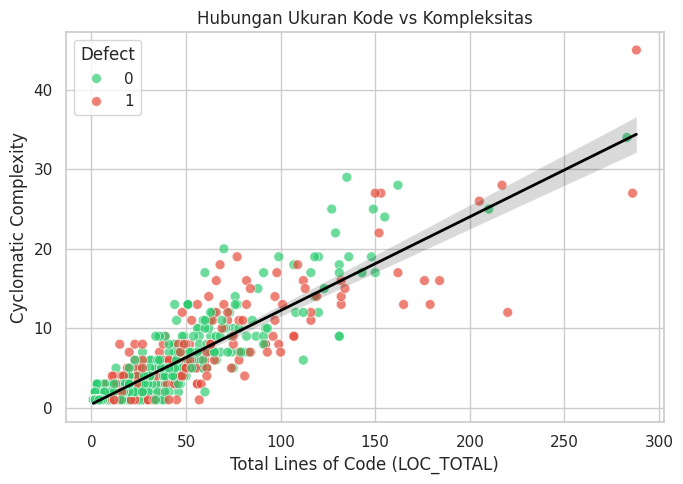

In [ ]:
# Grafik Scatter Plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='LOC_TOTAL', y='CYCLOMATIC_COMPLEXITY', hue='Defect', palette=['#2ecc71', '#e74c3c'], alpha=0.7, s=50)
sns.regplot(data=df, x='LOC_TOTAL', y='CYCLOMATIC_COMPLEXITY', scatter=False, color='black', line_kws={'linewidth': 2})
plt.title('Hubungan Ukuran Kode vs Kompleksitas')
plt.xlabel('Total Lines of Code (LOC_TOTAL)')
plt.ylabel('Cyclomatic Complexity')
plt.tight_layout()
plt.show()

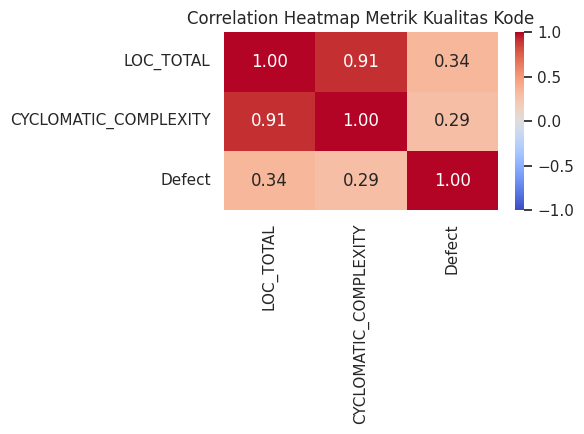

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(6, 4.5))
corr = df[['LOC_TOTAL', 'CYCLOMATIC_COMPLEXITY', 'Defect']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap Metrik Kualitas Kode')
plt.tight_layout()
plt.show()

In [ ]:
# Analisis Korelasi Spearman

from scipy import stats

correlation = stats.spearmanr(df['LOC_TOTAL'],  df['CYCLOMATIC_COMPLEXITY'])

print("=== KORELASI SPEARMAN ===")
print("Koefisien Spearman :", correlation.statistic)
print("p-value            :", correlation.pvalue)

=== KORELASI SPEARMAN ===
Koefisien Spearman : 0.8047183723706716
p-value            : 0.0
